# IEEE-CIS Fraud Detection: EDA

Здесь я сокращаю число `V`-признаков, изучаю время, суммы транзакций и пропуски. Основная метрика проекта — ROC-AUC.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from src.feature_selection import (
    find_correlated_groups,
    find_nan_groups,
    reduce_groups,
)

pd.set_option("display.max_columns", 200)
sns.set_theme(style="whitegrid")

## 1. Отбор V-признаков

`V1–V339` — анонимные инженерные признаки. Я объединяю признаки с одинаковым числом пропусков, нахожу внутри них группы с корреляцией выше 0.75 и оставляю из каждой группы признак с наибольшим числом уникальных значений.

In [2]:
transaction_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    *[f"C{i}" for i in range(1, 15)],
    *[f"D{i}" for i in range(1, 16)],
    *[f"M{i}" for i in range(1, 10)],
]

all_v_columns = [f"V{i}" for i in range(1, 340)]
v_dtypes = {column: "float32" for column in all_v_columns}

transaction_sample = pd.read_csv(
    "../data/train_transaction.csv",
    usecols=transaction_columns + all_v_columns + ["isFraud"],
    dtype=v_dtypes,
)

print("Исходная transaction-таблица:", transaction_sample.shape)

Исходная transaction-таблица: (590540, 394)


In [3]:
nan_groups = find_nan_groups(transaction_sample)
d_columns = [column for column in transaction_sample if column.startswith("D")]

selected_representatives = []

for columns in nan_groups.values():
    candidates = [
        column
        for column in columns
        if column in all_v_columns or column in d_columns
    ]

    if not candidates:
        continue

    correlation_groups = find_correlated_groups(
        transaction_sample,
        candidates,
        threshold=0.75,
    )
    selected_representatives.extend(
        reduce_groups(transaction_sample, correlation_groups)
    )

selected_v_columns = [
    column
    for column in selected_representatives
    if column.startswith("V")
]

print(f"V-признаков до отбора: {len(all_v_columns)}")
print(f"V-признаков после отбора: {len(selected_v_columns)}")

V-признаков до отбора: 339
V-признаков после отбора: 108


## 2. Загрузка данных

Объединяю transaction и identity по `TransactionID`. Числовые признаки загружаю как `float32`, чтобы уменьшить расход памяти.

In [4]:
categorical_columns = [
    "ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28", "id_29",
    "id_30", "id_31", "id_33", "id_34", "id_35", "id_36", "id_37",
    "id_38", "DeviceType", "DeviceInfo",
    "id-12", "id-15", "id-16", "id-23", "id-27", "id-28", "id-29",
    "id-30", "id-31", "id-33", "id-34", "id-35", "id-36", "id-37",
    "id-38",
]

model_transaction_columns = transaction_columns + selected_v_columns

train_identity_columns = [
    *[f"id_{i:02d}" for i in range(1, 10)],
    *[f"id_{i}" for i in range(10, 39)],
]
test_identity_columns = [column.replace("_", "-") for column in train_identity_columns]

dtypes = {
    column: "float32"
    for column in (
        model_transaction_columns
        + train_identity_columns
        + test_identity_columns
    )
}
dtypes.update({column: "category" for column in categorical_columns})
dtypes["TransactionID"] = "int32"
dtypes["isFraud"] = "int8"

In [5]:
X_train = pd.read_csv(
    "../data/train_transaction.csv",
    index_col="TransactionID",
    usecols=model_transaction_columns + ["isFraud"],
    dtype=dtypes,
)
train_identity = pd.read_csv(
    "../data/train_identity.csv",
    index_col="TransactionID",
    dtype=dtypes,
)
X_train = X_train.join(train_identity, how="left")

X_test = pd.read_csv(
    "../data/test_transaction.csv",
    index_col="TransactionID",
    usecols=model_transaction_columns,
    dtype=dtypes,
)
test_identity = pd.read_csv(
    "../data/test_identity.csv",
    index_col="TransactionID",
    dtype=dtypes,
)
test_identity.columns = test_identity.columns.str.replace("-", "_", regex=False)
X_test = X_test.join(test_identity, how="left")

y_train = X_train.pop("isFraud")

del transaction_sample, train_identity, test_identity

print("Train:", X_train.shape)
print("Test: ", X_test.shape)
print(f"Fraud rate: {y_train.mean():.2%}")

Train: (590540, 201)
Test:  (506691, 201)
Fraud rate: 3.50%


В train 590 540 строк и только около 3.5% fraud. Поэтому accuracy здесь мало полезна.

## 3. Время

`TransactionDT` — число секунд от неизвестной даты. Train и test идут друг за другом во времени, поэтому для модели понадобится временная валидация.

In [6]:
SECONDS_PER_DAY = 86400
SECONDS_PER_WEEK = 7 * SECONDS_PER_DAY
train_start = X_train["TransactionDT"].min()

train_time = X_train[["TransactionDT", "TransactionAmt"]].copy()
train_time["isFraud"] = y_train
train_time["relative_day"] = (train_time["TransactionDT"] // SECONDS_PER_DAY).astype("int16")
train_time["relative_week"] = (
    (train_time["TransactionDT"] - train_start) // SECONDS_PER_WEEK
).astype("int8")
train_time["relative_hour"] = (
    (train_time["TransactionDT"] // 3600) % 24
).astype("int8")

test_time = X_test[["TransactionDT", "TransactionAmt"]].copy()
test_time["relative_day"] = (test_time["TransactionDT"] // SECONDS_PER_DAY).astype("int16")
test_time["relative_week"] = (
    (test_time["TransactionDT"] - train_start) // SECONDS_PER_WEEK
).astype("int8")
test_time["relative_hour"] = (
    (test_time["TransactionDT"] // 3600) % 24
).astype("int8")

time_summary = pd.DataFrame({
    "dataset": ["train", "test"],
    "first_day": [train_time["relative_day"].min(), test_time["relative_day"].min()],
    "last_day": [train_time["relative_day"].max(), test_time["relative_day"].max()],
    "unique_days": [train_time["relative_day"].nunique(), test_time["relative_day"].nunique()],
})

exact_gap_days = (
    X_test["TransactionDT"].min() - X_train["TransactionDT"].max()
) / SECONDS_PER_DAY

display(time_summary)
print(f"Точный разрыв между train и test: {exact_gap_days:.2f} дня")

,dataset,first_day,last_day,unique_days
0,train,1,182,182
1,test,213,395,183


Точный разрыв между train и test: 30.00 дня


In [7]:
train_daily = (
    train_time.groupby("relative_day", as_index=False)
    .size()
    .rename(columns={"size": "transaction_cnt"})
    .assign(dataset="train")
)
test_daily = (
    test_time.groupby("relative_day", as_index=False)
    .size()
    .rename(columns={"size": "transaction_cnt"})
    .assign(dataset="test")
)
daily_transactions = pd.concat([train_daily, test_daily], ignore_index=True)

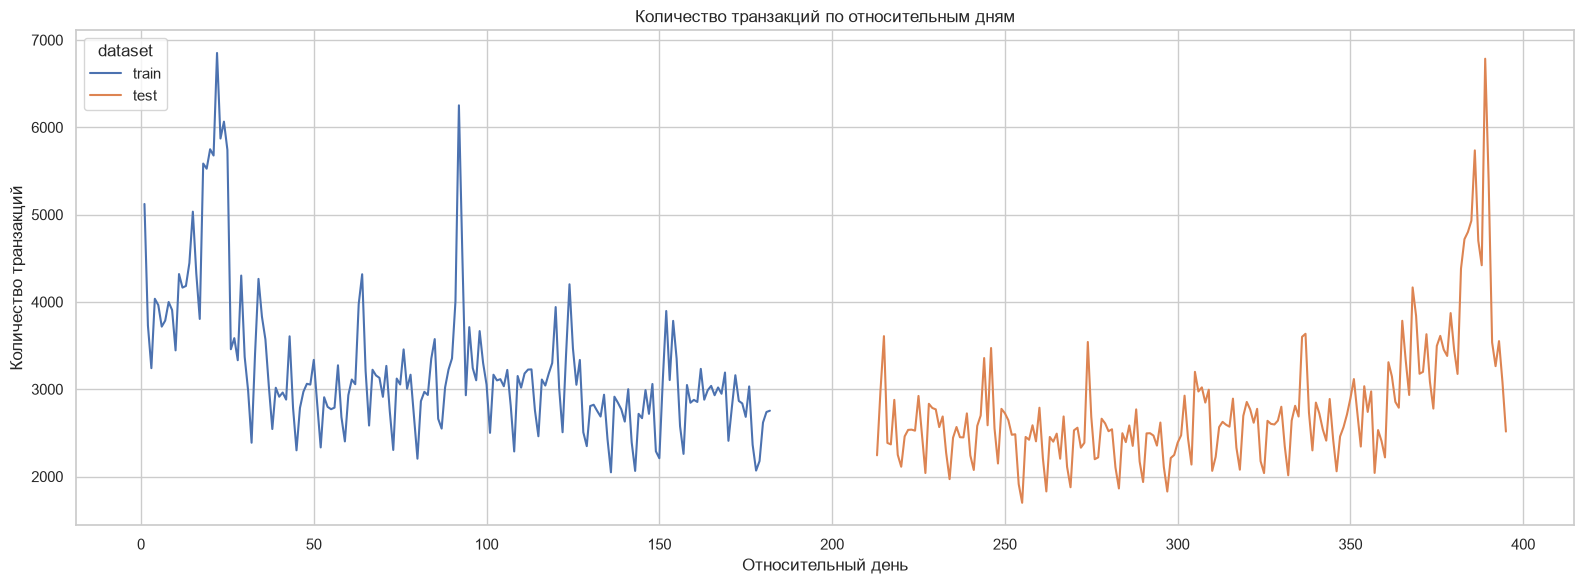

In [8]:
plt.figure(figsize=(16, 6))
sns.lineplot(
    data=daily_transactions,
    x="relative_day",
    y="transaction_cnt",
    hue="dataset"
)
plt.title("Количество транзакций по относительным дням")
plt.xlabel("Относительный день")
plt.ylabel("Количество транзакций")
plt.tight_layout()
plt.show()

Train занимает дни 1–182, test — 213–395. Между ними около 30 дней, а число транзакций со временем меняется.

In [9]:
weekly_stats = (
    train_time.groupby("relative_week", as_index=False)
    .agg(
        transaction_cnt=("isFraud", "size"),
        fraud_cnt=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
)

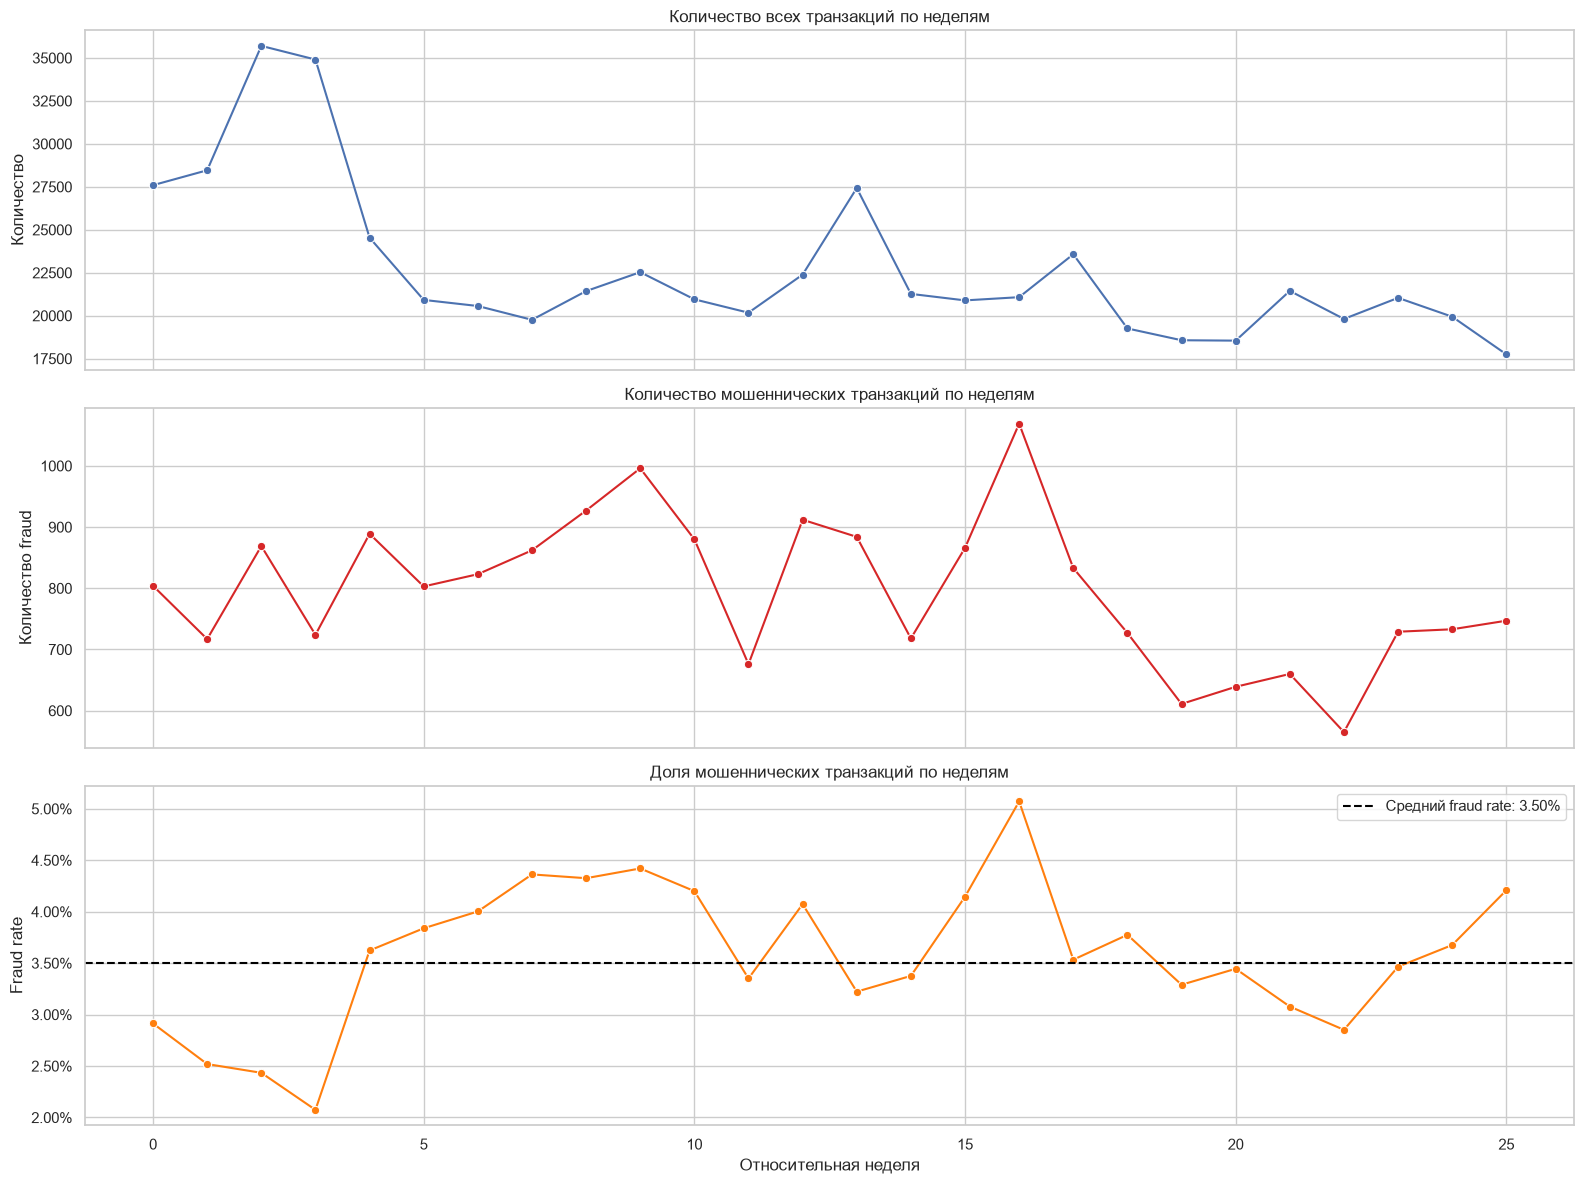

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

sns.lineplot(data=weekly_stats, x="relative_week", y="transaction_cnt", marker="o", ax=axes[0])
axes[0].set_title("Количество всех транзакций по неделям")
axes[0].set_ylabel("Количество")

sns.lineplot(
    data=weekly_stats,
    x="relative_week",
    y="fraud_cnt",
    marker="o",
    color="tab:red",
    ax=axes[1],
)
axes[1].set_title("Количество мошеннических транзакций по неделям")
axes[1].set_ylabel("Количество fraud")

sns.lineplot(
    data=weekly_stats,
    x="relative_week",
    y="fraud_rate",
    marker="o",
    color="tab:orange",
    ax=axes[2],
)
axes[2].axhline(
    y_train.mean(),
    color="black",
    linestyle="--",
    label=f"Средний fraud rate: {y_train.mean():.2%}",
)
axes[2].set_title("Доля мошеннических транзакций по неделям")
axes[2].set_xlabel("Относительная неделя")
axes[2].set_ylabel("Fraud rate")
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
axes[2].legend()

plt.tight_layout()
plt.show()

Fraud rate меняется от недели к неделе. Это ещё один аргумент в пользу временной валидации.

In [11]:
hour_stats = (
    train_time.groupby("relative_hour", as_index=False)
    .agg(
        transaction_cnt=("isFraud", "size"),
        fraud_rate=("isFraud", "mean"),
    )
)

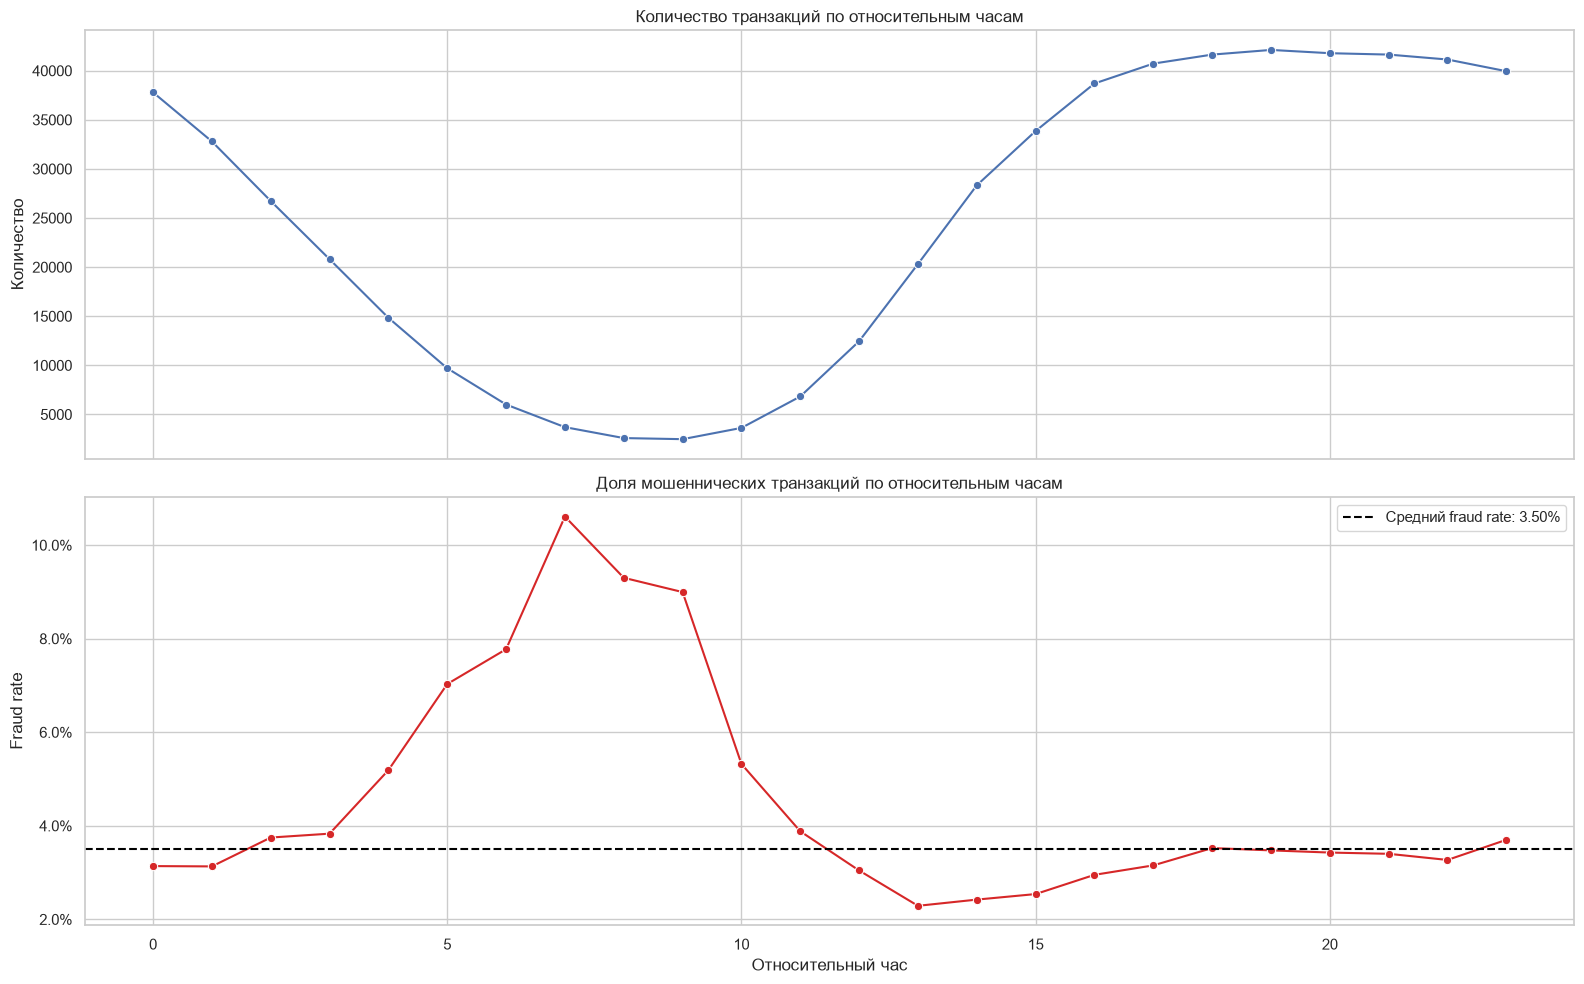

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

sns.lineplot(data=hour_stats, x="relative_hour", y="transaction_cnt", marker="o", ax=axes[0])
axes[0].set_title("Количество транзакций по относительным часам")
axes[0].set_ylabel("Количество")

sns.lineplot(
    data=hour_stats,
    x="relative_hour",
    y="fraud_rate",
    marker="o",
    color="tab:red",
    ax=axes[1],
)
axes[1].axhline(
    y_train.mean(),
    color="black",
    linestyle="--",
    label=f"Средний fraud rate: {y_train.mean():.2%}",
)
axes[1].set_title("Доля мошеннических транзакций по относительным часам")
axes[1].set_xlabel("Относительный час")
axes[1].set_ylabel("Fraud rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()

plt.tight_layout()
plt.show()

Fraud rate зависит и от часа. Позже проверим циклические признаки часа и дня недели.

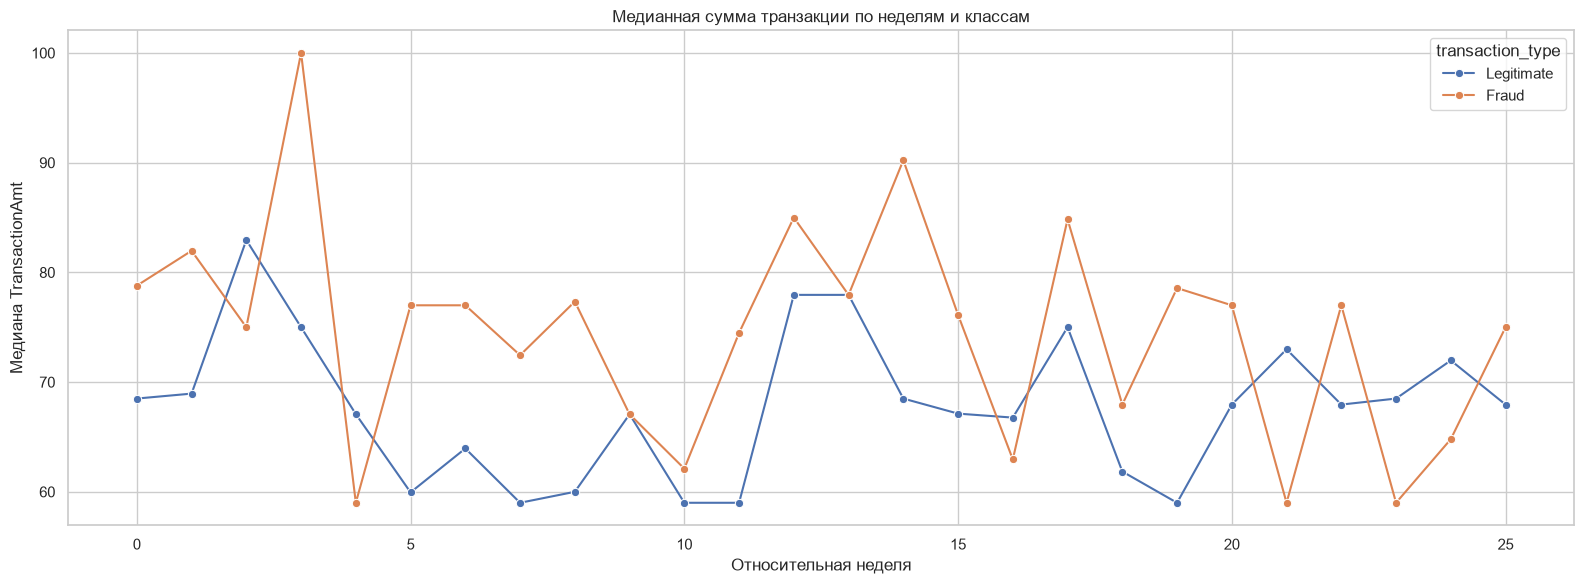

In [13]:
weekly_amount_by_target = (
    train_time.groupby(["relative_week", "isFraud"], as_index=False)
    .agg(
        transaction_count=("TransactionAmt", "size"),
        median_amount=("TransactionAmt", "median"),
    )
)
weekly_amount_by_target["transaction_type"] = weekly_amount_by_target["isFraud"].map(
    {0: "Legitimate", 1: "Fraud"}
)

plt.figure(figsize=(16, 6))
sns.lineplot(
    data=weekly_amount_by_target,
    x="relative_week",
    y="median_amount",
    hue="transaction_type",
    marker="o",
)
plt.title("Медианная сумма транзакции по неделям и классам")
plt.xlabel("Относительная неделя")
plt.ylabel("Медиана TransactionAmt")
plt.tight_layout()
plt.show()

Суммы fraud-транзакций часто выше, но связь меняется со временем.

## 4. Временная валидация

Используем два development-фолда и отдельный final holdout. Между train и validation оставляем gap в 30 дней.

| Этап | Обучение | Gap | Валидация |
|---|---:|---:|---:|
| Fold 1 | дни 1–62 | 63–92 | 93–122 |
| Fold 2 | дни 1–92 | 93–122 | 123–152 |
| Final holdout | дни 1–122 | 123–152 | 153–182 |

Final holdout не используем при выборе признаков и параметров.

## 5. Пропуски и identity

Сравним доли пропусков в train и test. Удалять столбцы только из-за большого числа пропусков не будем: для деревьев сам пропуск может быть полезным сигналом.

In [14]:
missing_report = pd.DataFrame({
    "feature": X_train.columns,
    "dtype": X_train.dtypes.astype(str).to_numpy(),
    "train_missing_count": X_train.isna().sum().to_numpy(),
    "train_missing_rate": X_train.isna().mean().to_numpy(),
    "test_missing_count": X_test.isna().sum().to_numpy(),
    "test_missing_rate": X_test.isna().mean().to_numpy(),
    "train_nunique": X_train.nunique().to_numpy(),
    "test_nunique": X_test.nunique().to_numpy(),
})
missing_report["missing_rate_diff"] = (
    missing_report["test_missing_rate"] - missing_report["train_missing_rate"]
)
missing_report["abs_missing_rate_diff"] = missing_report["missing_rate_diff"].abs()

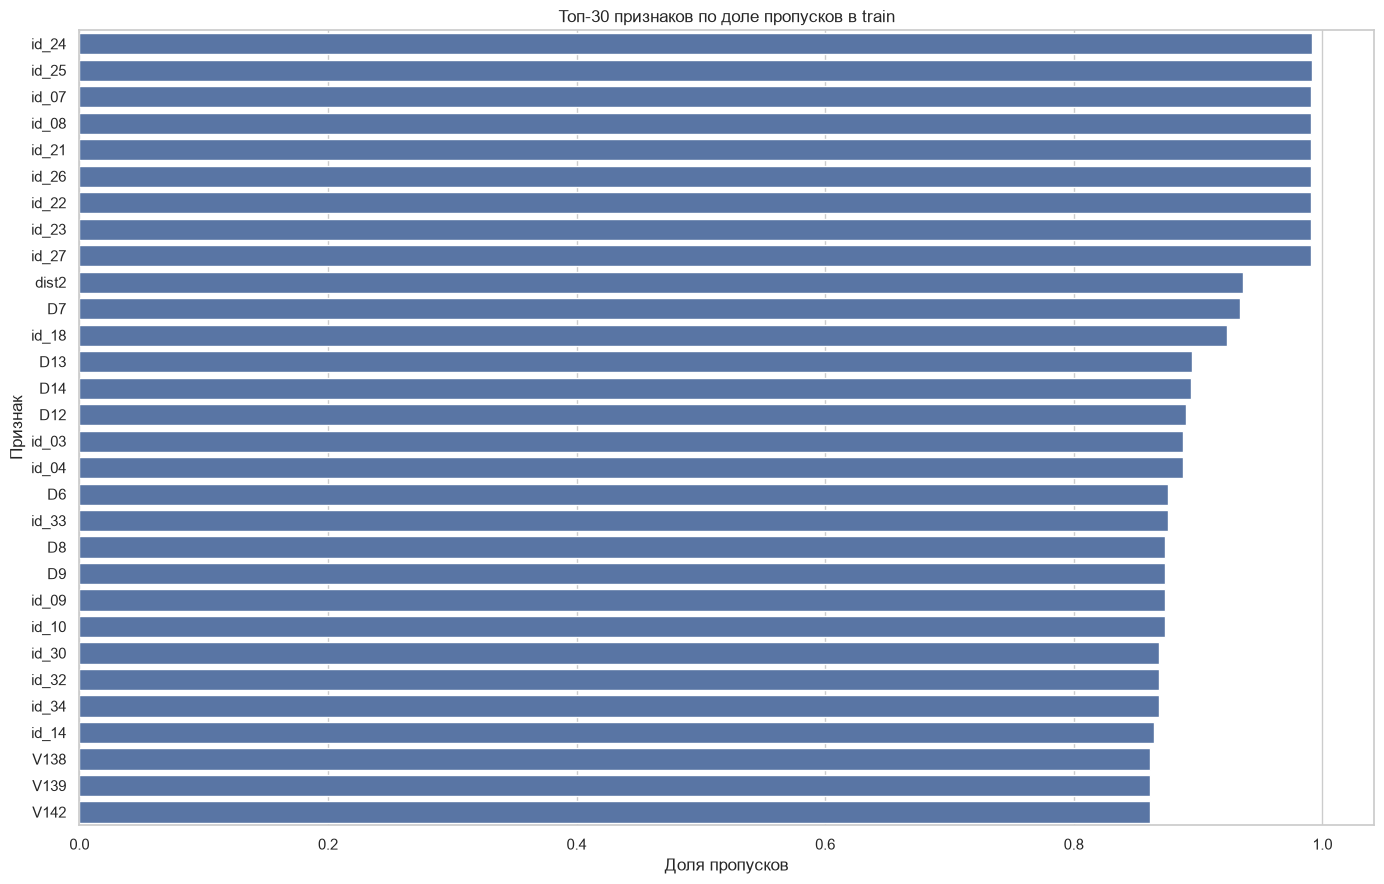

In [15]:
top_missing = missing_report.nlargest(30, "train_missing_rate")

plt.figure(figsize=(14, 9))
sns.barplot(data=top_missing, x="train_missing_rate", y="feature")
plt.title("Топ-30 признаков по доле пропусков в train")
plt.xlabel("Доля пропусков")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

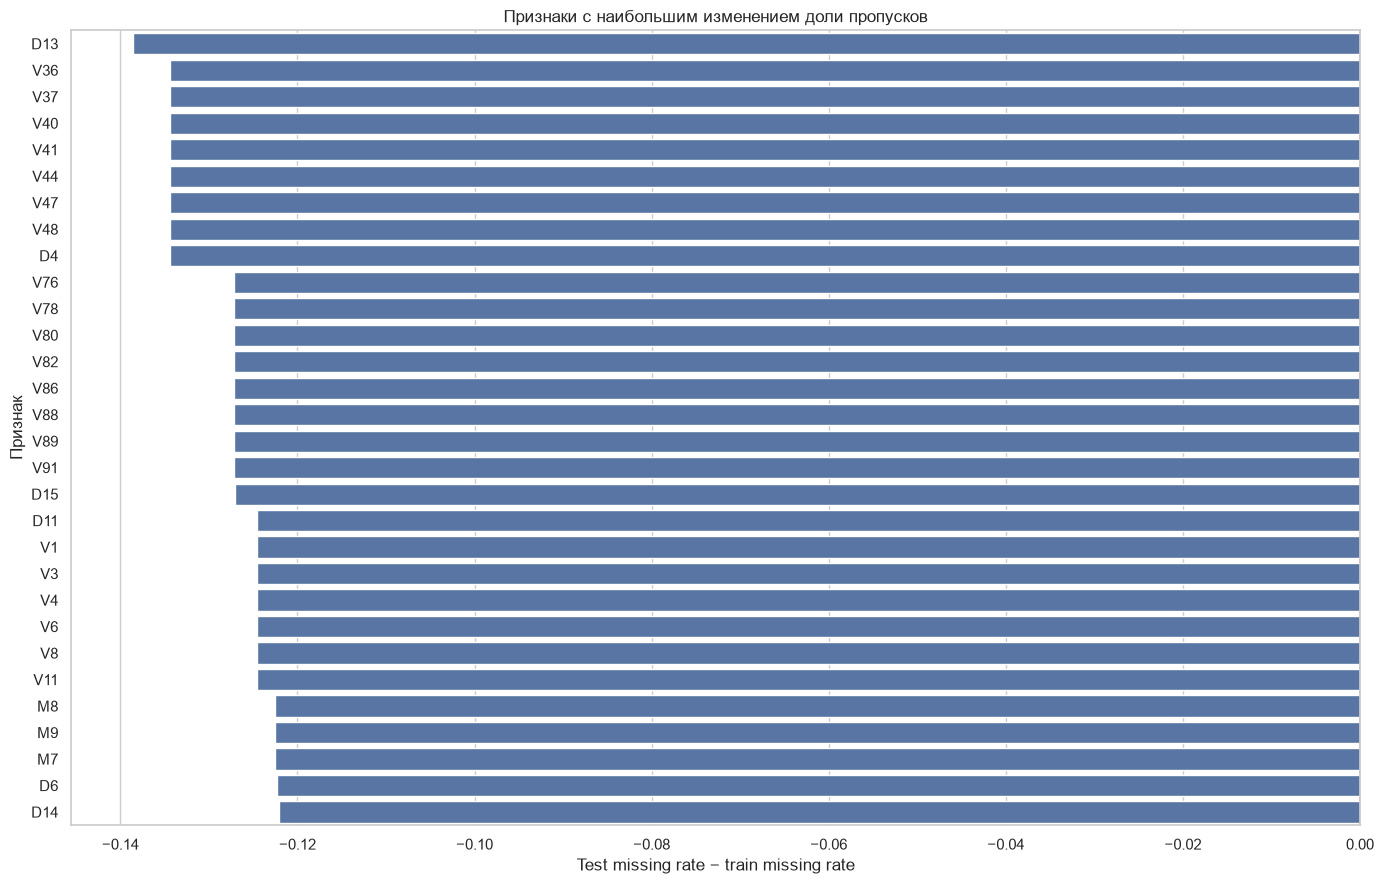

In [16]:
top_missing_shift = (
    missing_report.nlargest(30, "abs_missing_rate_diff")
    .sort_values("missing_rate_diff")
)

plt.figure(figsize=(14, 9))
sns.barplot(data=top_missing_shift, x="missing_rate_diff", y="feature")
plt.axvline(0, color="black", linewidth=1)
plt.title("Признаки с наибольшим изменением доли пропусков")
plt.xlabel("Test missing rate − train missing rate")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Доли пропусков некоторых `D`, `V` и `M`-признаков заметно меняются между train и test. Это похоже на временной сдвиг данных.

### Наличие identity

Флаг `has_identity` показывает, есть ли у транзакции хотя бы один identity-признак.

In [17]:
identity_columns = [
    column
    for column in X_train.columns
    if column.startswith("id_") or column in {"DeviceType", "DeviceInfo"}
]

train_has_identity = X_train[identity_columns].notna().any(axis=1).rename("has_identity")
test_has_identity = X_test[identity_columns].notna().any(axis=1).rename("has_identity")

identity_summary = pd.DataFrame({
    "dataset": ["train", "test"],
    "transaction_count": [len(X_train), len(X_test)],
    "identity_count": [train_has_identity.sum(), test_has_identity.sum()],
    "identity_rate": [train_has_identity.mean(), test_has_identity.mean()],
})

identity_summary

,dataset,transaction_count,identity_count,identity_rate
0,train,590540,144233,0.244239
1,test,506691,141907,0.280066


In [18]:
identity_fraud = pd.DataFrame({
    "has_identity": train_has_identity,
    "isFraud": y_train,
})

identity_fraud_stats = (
    identity_fraud.groupby("has_identity", as_index=False)
    .agg(
        transaction_count=("isFraud", "size"),
        fraud_count=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
)

identity_fraud_stats

,has_identity,transaction_count,fraud_count,fraud_rate
0,False,446307,9345,0.020939
1,True,144233,11318,0.078470


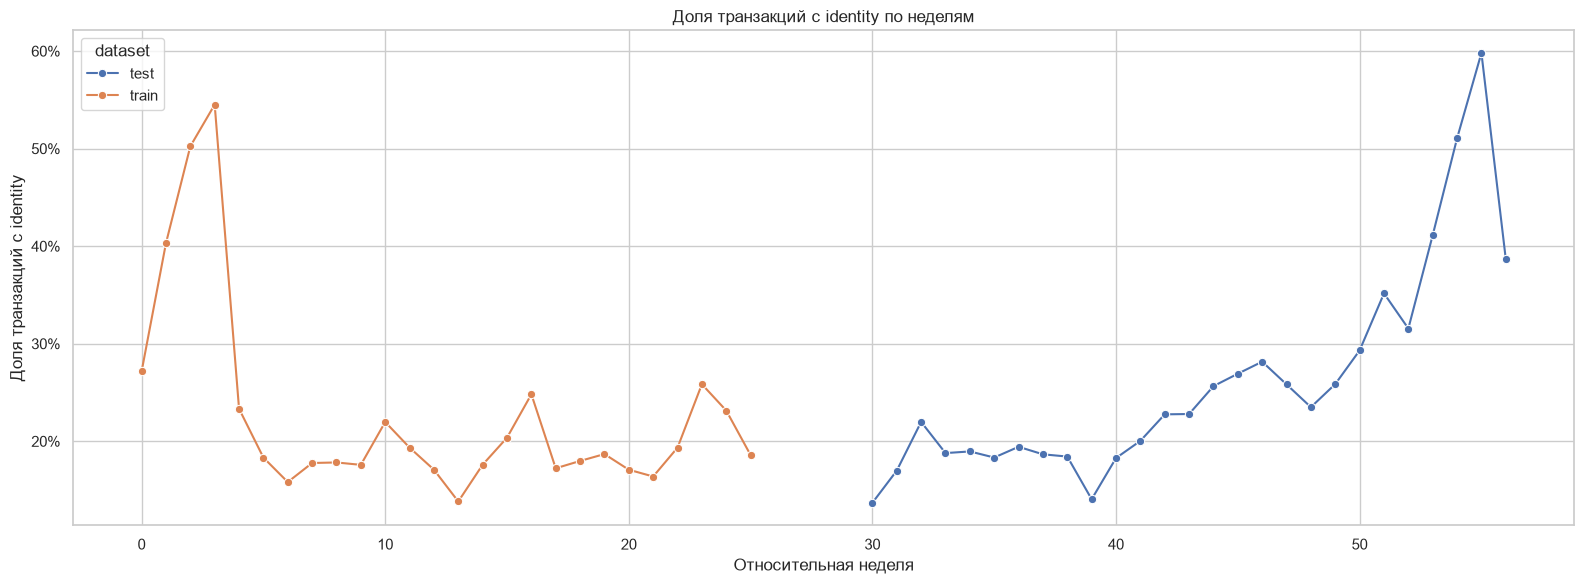

In [19]:
train_identity_time = X_train[["TransactionDT"]].copy()
train_identity_time["has_identity"] = train_has_identity
train_identity_time["dataset"] = "train"

test_identity_time = X_test[["TransactionDT"]].copy()
test_identity_time["has_identity"] = test_has_identity
test_identity_time["dataset"] = "test"

identity_time = pd.concat(
    [train_identity_time, test_identity_time],
    ignore_index=True,
)
identity_time["relative_week"] = (
    (identity_time["TransactionDT"] - train_start) // SECONDS_PER_WEEK
).astype("int8")

weekly_identity = (
    identity_time.groupby(["dataset", "relative_week"], as_index=False)
    .agg(
        transaction_count=("has_identity", "size"),
        identity_count=("has_identity", "sum"),
        identity_rate=("has_identity", "mean"),
    )
)

plt.figure(figsize=(16, 6))
sns.lineplot(
    data=weekly_identity,
    x="relative_week",
    y="identity_rate",
    hue="dataset",
    marker="o",
)
plt.title("Доля транзакций с identity по неделям")
plt.xlabel("Относительная неделя")
plt.ylabel("Доля транзакций с identity")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

Identity есть у 24.4% train и 28.0% test. Fraud rate составляет около 7.85% при наличии identity и 2.09% без неё.

## Итоги

- Из 339 `V`-признаков осталось 108.
- Доля fraud — около 3.5%.
- Между train и test есть временной разрыв и сдвиг распределений.
- Время, пропуски и наличие identity могут быть полезны модели.
- Для экспериментов используем временные фолды с gap.